In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer

<h2>1. Diabetes Dataset – Missing Value Imputation & Encoding.</h2>
   
Dataset Link:
        [Pima Indians Diabetes Dataset](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database?utm_source=chatgpt.com)

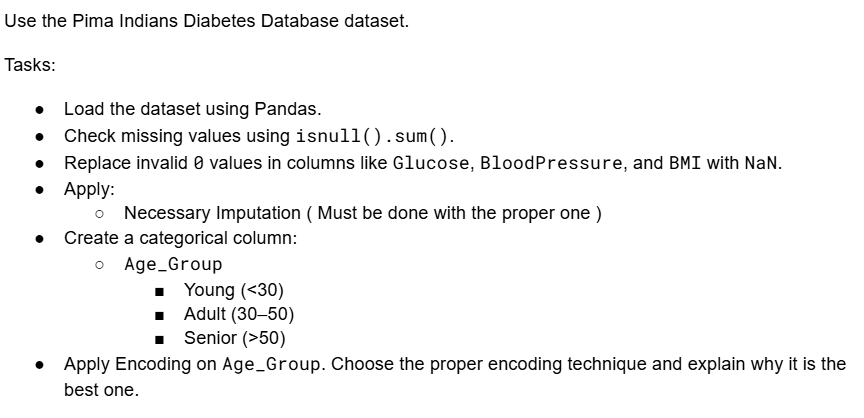

In [2]:
df=pd.read_csv('diabetes.csv')
df.sample(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
413,1,143,74,22,61,26.2,0.256,21,0
124,0,113,76,0,0,33.3,0.278,23,1
689,1,144,82,46,180,46.1,0.335,46,1
476,2,105,80,45,191,33.7,0.711,29,1
298,14,100,78,25,184,36.6,0.412,46,1


In [3]:
col_to_check=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']

imputer=SimpleImputer(missing_values=pd.NA, strategy='median')

for col in col_to_check:
    df[col].replace(0,pd.NA)
    df[col]=imputer.fit_transform(df[[col]])
    # print((df[col].value_counts().sort_index()))
    # print((df[col]==0).sum())
    # print(df[col][df[col]!=0].median())
    print(df[col].skew())


0.17375350179188992
-1.8436079833551302
0.10937249648187608
2.272250858431574
-0.42898158845356543


In [4]:
# another way to do imputation

transformer=ColumnTransformer(
    transformers = [
        ('imputer', SimpleImputer(missing_values=pd.NA, strategy='median'),col_to_check)
    ],verbose_feature_names_out=False,
    remainder='passthrough')
transformer.set_output(transform='pandas')

df=transformer.fit_transform(df)
df.sample()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pregnancies,DiabetesPedigreeFunction,Age,Outcome
698,127.0,88.0,11.0,155.0,34.5,4,0.598,28,0


In [5]:
df.sample(10)

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pregnancies,DiabetesPedigreeFunction,Age,Outcome
303,115.0,98.0,0.0,0.0,52.9,5,0.209,28,1
456,135.0,54.0,0.0,0.0,26.7,1,0.687,62,0
578,133.0,68.0,0.0,0.0,27.0,10,0.245,36,0
385,119.0,54.0,13.0,50.0,22.3,1,0.205,24,0
182,0.0,74.0,20.0,23.0,27.7,1,0.299,21,0
599,109.0,38.0,18.0,120.0,23.1,1,0.407,26,0
64,114.0,66.0,0.0,0.0,32.8,7,0.258,42,1
695,142.0,90.0,24.0,480.0,30.4,7,0.128,43,1
156,99.0,52.0,15.0,94.0,24.6,2,0.637,21,0
471,137.0,70.0,38.0,0.0,33.2,0,0.170,22,0


In [6]:
df.loc[df['Age']<30,['Age_Group']]='Young'

In [7]:
df.loc[(df['Age']>=30)&(df['Age']<=50),'Age_Group']='Adult'

In [8]:
df.loc[df['Age']>50,['Age_Group']]='Senior'

In [9]:
# age_group_encoder=OrdinalEncoder(categories=[['Young','Adult','Senior']])
# age_group_encoder.fit(df[['Age_Group']])
# df['encoded_age_group']=age_group_encoder.transform(df[['Age_Group']]).ravel()

In [10]:
encodertransformer=ColumnTransformer(
    transformers = [
        ('encoder', OrdinalEncoder(categories=[['Young','Adult','Senior']]),['Age_Group'])
    ],
    verbose_feature_names_out=False,
    remainder='passthrough'
)
encodertransformer.set_output(transform='pandas')

df=encodertransformer.fit_transform(df)
df.sample()

,Age_Group,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pregnancies,DiabetesPedigreeFunction,Age,Outcome
300,1.0,167.0,0.0,0.0,0.0,32.3,0,0.839,30,1


In [11]:
# df=df.drop('encoded_age_group',axis=1)
df.sample()

,Age_Group,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pregnancies,DiabetesPedigreeFunction,Age,Outcome
27,0.0,97.0,66.0,15.0,140.0,23.2,1,0.487,22,0


<h2>2. Heart Disease Dataset – One Hot Encoding.</h2>

   Dataset Link:
[Heart Disease UCI Dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset?utm_source=chatgpt.com)

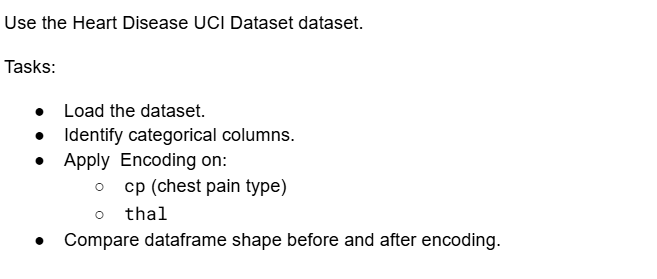


<h2>3. Tips Dataset – Label Encoding</h2>

Dataset Link: [Seaborn Tips Dataset](https://github.com/mwaskom/seaborn-data/blob/master/tips.csv?utm_source=chatgpt.com)

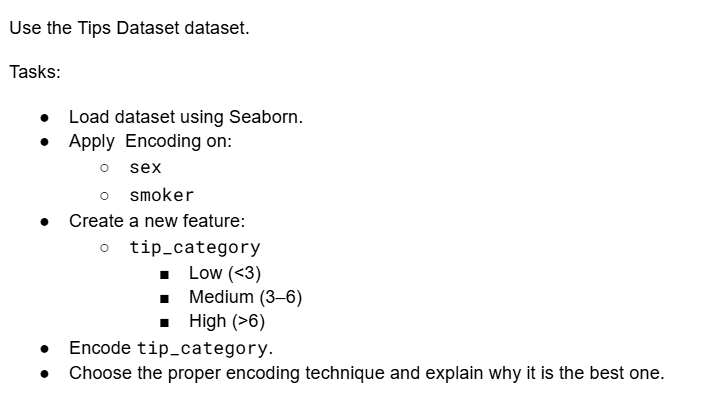

<h2>4. Car Price Dataset – Train/Test Encoding Pipeline</h2>

Dataset Link: [Car Price Prediction Dataset](https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?utm_source=chatgpt.com)

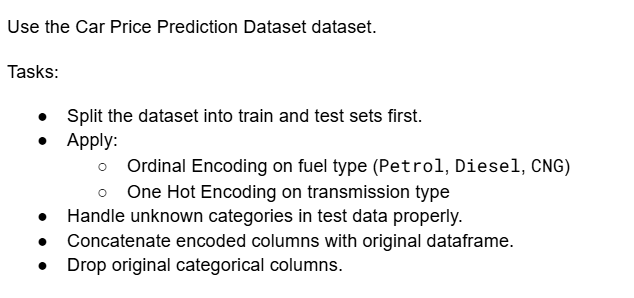

<h2>5. Heart Disease Dataset </h2>


Dataset Link: [Heart Disease UCI Dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset?utm_source=chatgpt.com)


Use the Heart Disease UCI Dataset dataset.
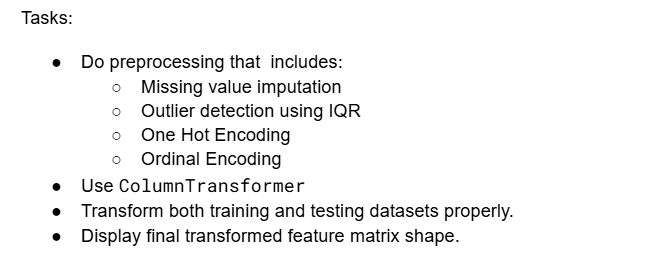

<h2> 6. Diabetes Dataset – Compare Encoding Techniques</h2>

Dataset Link: [Pima Indians Diabetes Dataset](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database?utm_source=chatgpt.com)

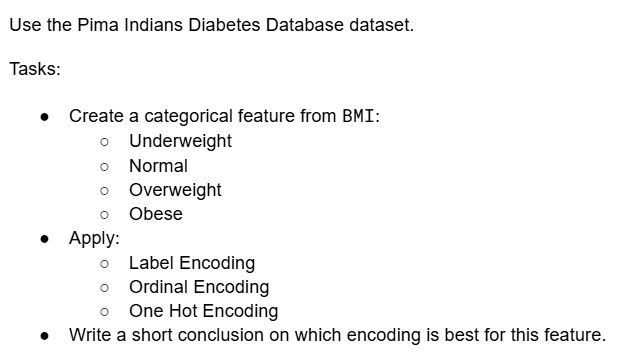

<h2> 7. Hotel Booking Dataset – High Cardinality Encoding</h2>

Dataset Link: [Hotel Booking Demand Dataset](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand?utm_source=chatgpt.com)

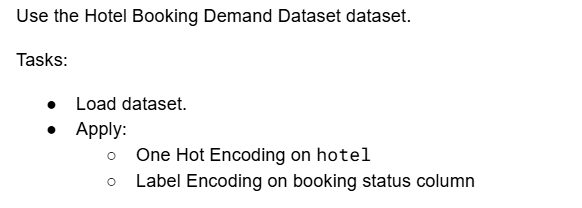

<h2>8. Employee Attrition Dataset – Advanced Encoding Challenge</h2>

Dataset Link: [IBM HR Analytics Employee Attrition Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset?utm_source=chatgpt.com)

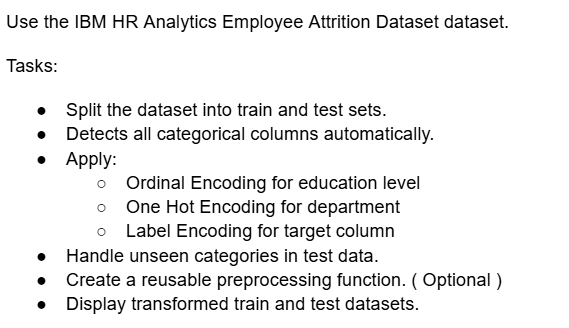